<a href="https://colab.research.google.com/github/Wasayyyyyy/CV-Tasks/blob/main/43_AbdulWasay_LabMid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Mid Exam — HOG vs SIFT on Blood-Cell Images
**Name:** Abdul Wasay  **Reg. No:** FA23-BAI-043  **Course:** Computer Vision Lab

**Goal:** build two classical pipelines (HOG + SVM and SIFT + SVM) and test which one stays more reliable when images are rotated or noisy.

### My personal settings (reg. no. 043 → last digit 3)
| Setting | Rule | My value |
|---|---|---|
| Random seed | last two digits | **43** |
| HOG cell size | last digit odd → 16 × 16 | **16 × 16** |
| SIFT grid | last digit 0–4 → 4 × 4 grid | **4 × 4 (16 keypoints)** |

In [1]:
# ---- My personal settings (from registration number 043) ----
SEED      = 43        # last two digits
HOG_CELL  = (16, 16)  # last digit 3 is odd  -> 16 x 16
GRID      = 4         # last digit 3 is in 0-4 -> 4 x 4 grid = 16 keypoints

# ---- Fixed settings for everyone ----
CLASSES     = [1, 5, 6, 7]   # BloodMNIST label numbers
CLASS_NAMES = {1: 'eosinophil', 5: 'monocyte', 6: 'neutrophil', 7: 'platelet'}
N_TRAIN, N_VAL, N_TEST = 100, 30, 30
IMG_SIZE    = 128
C_VALUES    = [0.1, 1, 10]
ROT_ANGLE   = 20
NOISE_SIGMA = 0.05

In [2]:
# Install the dataset package (only needed once, e.g. on Colab)
!pip install -q medmnist

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from medmnist import BloodMNIST

np.random.seed(SEED)
names = [CLASS_NAMES[c] for c in CLASSES]   # class names in order, used for plots

## Q1. Data Setup
Steps: load each split → keep only the 4 classes → randomly pick 100 / 30 / 30 images per class with my seed → convert to grayscale → resize to 128 × 128.

In [4]:
def load_split(split, n_per_class):
    data = BloodMNIST(split=split, download=True, size=64)
    imgs, labels = data.imgs, data.labels.flatten()      # imgs: (N, 64, 64, 3)

    rng = np.random.default_rng(SEED)
    X, y = [], []
    for c in CLASSES:
        idx = np.where(labels == c)[0]                    # all images of class c
        chosen = rng.choice(idx, n_per_class, replace=False)
        for i in chosen:
            gray = cv2.cvtColor(imgs[i], cv2.COLOR_RGB2GRAY)        # colour -> grayscale
            gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))           # 64 -> 128
            X.append(gray)
            y.append(c)
    return np.array(X), np.array(y)

X_train, y_train = load_split('train', N_TRAIN)
X_val,   y_val   = load_split('val',   N_VAL)
X_test,  y_test  = load_split('test',  N_TEST)

for name, X, y in [('Train', X_train, y_train), ('Val', X_val, y_val), ('Test', X_test, y_test)]:
    counts = {CLASS_NAMES[c]: int((y == c).sum()) for c in CLASSES}
    print(f'{name:5s} shape: {X.shape}  counts: {counts}')

100%|██████████| 156M/156M [01:51<00:00, 1.40MB/s]


Train shape: (400, 128, 128)  counts: {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
Val   shape: (120, 128, 128)  counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
Test  shape: (120, 128, 128)  counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


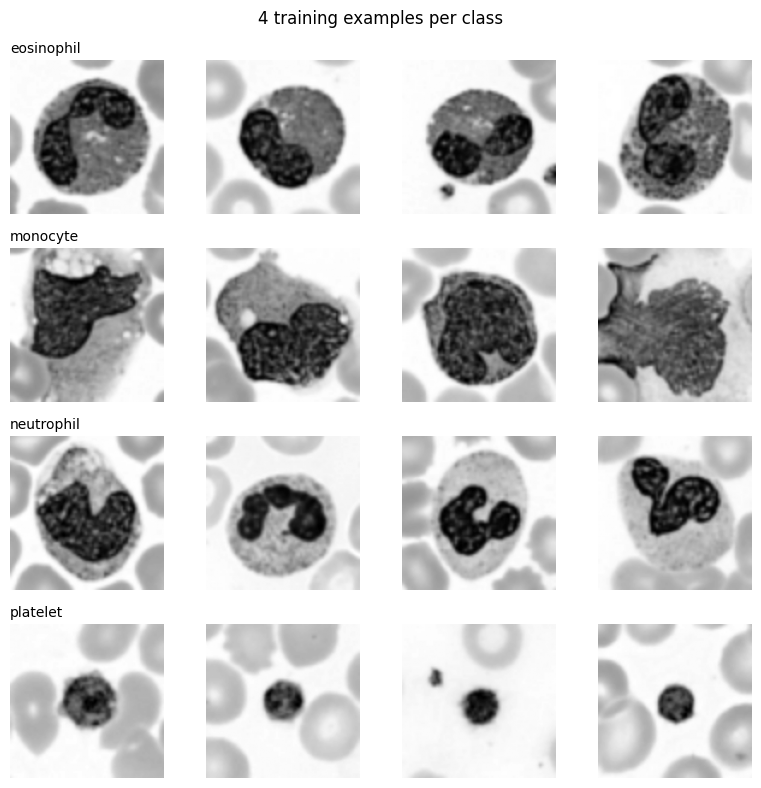

In [5]:
# Grid: 4 example images per class (rows = classes)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r, c in enumerate(CLASSES):
    examples = X_train[y_train == c][:4]
    for k in range(4):
        axes[r, k].imshow(examples[k], cmap='gray')
        axes[r, k].axis('off')
    axes[r, 0].set_title(CLASS_NAMES[c], loc='left', fontsize=10)
plt.suptitle('4 training examples per class')
plt.tight_layout()
plt.show()

## Q2. HOG + SVM
### Q2(a) HOG features

In [6]:
def hog_features(img):
    return hog(img, orientations=9, pixels_per_cell=HOG_CELL, cells_per_block=(2, 2))

def hog_all(X):
    return np.array([hog_features(img) for img in X])

H_train, H_val = hog_all(X_train), hog_all(X_val)
print('HOG feature length:', H_train.shape[1])
print('HOG train matrix:', H_train.shape, ' val matrix:', H_val.shape)

HOG feature length: 1764
HOG train matrix: (400, 1764)  val matrix: (120, 1764)


**Feature length by hand (cell 16 × 16):**
- Cells per side = 128 / 16 = **8** → 8 × 8 cells
- A block is 2 × 2 cells and slides one cell at a time → blocks per side = 8 − 2 + 1 = **7** → 7 × 7 = **49 blocks**
- Values per block = 2 × 2 cells × 9 orientations = **36**
- Total = 49 × 36 = **1764** ✅ (matches the printed length)

### Q2(b) HOG picture for one image per class

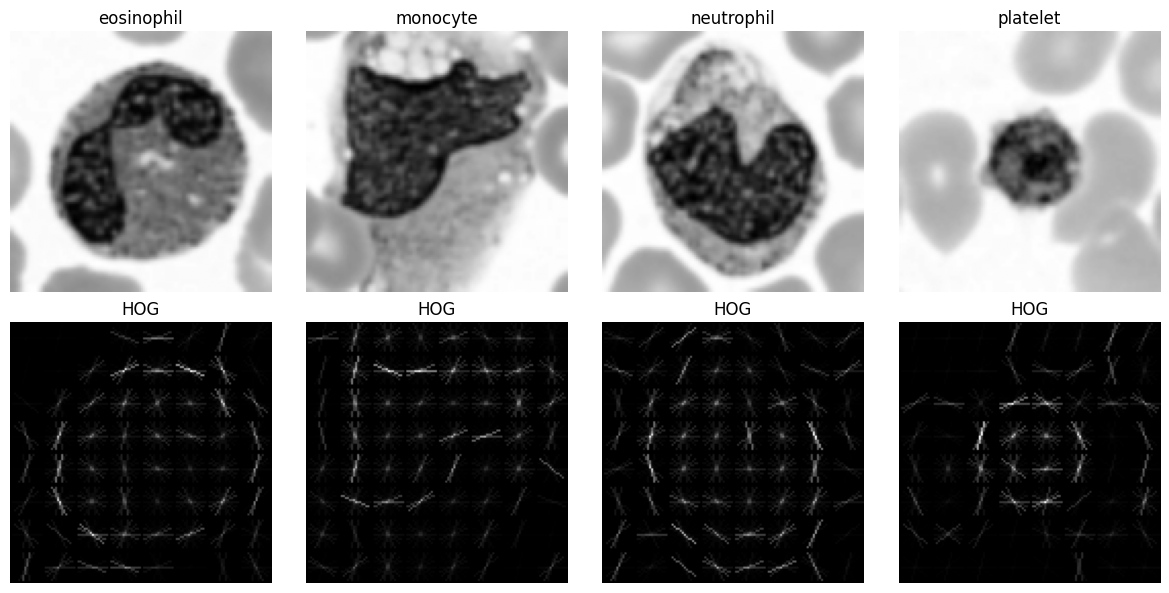

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for k, c in enumerate(CLASSES):
    img = X_train[y_train == c][0]
    _, hog_img = hog(img, orientations=9, pixels_per_cell=HOG_CELL,
                     cells_per_block=(2, 2), visualize=True)
    axes[0, k].imshow(img, cmap='gray');     axes[0, k].set_title(CLASS_NAMES[c])
    axes[1, k].imshow(hog_img, cmap='gray'); axes[1, k].set_title('HOG')
    axes[0, k].axis('off'); axes[1, k].axis('off')
plt.tight_layout()
plt.show()

### Q2(c) Train SVM and choose C on the validation set
One helper is used for **both** HOG and SIFT: try each C, train on train, score on validation, keep the best.
`StandardScaler` puts every feature on the same scale so LinearSVC trains properly (it is fitted on the training data only).

HOG + SVM:
  C = 0.1  -> validation accuracy = 0.7250
  C = 1    -> validation accuracy = 0.7250
  C = 10   -> validation accuracy = 0.7250
Best C: 0.1
HOG + SVM | Validation accuracy: 0.7250 | Macro-F1: 0.7175


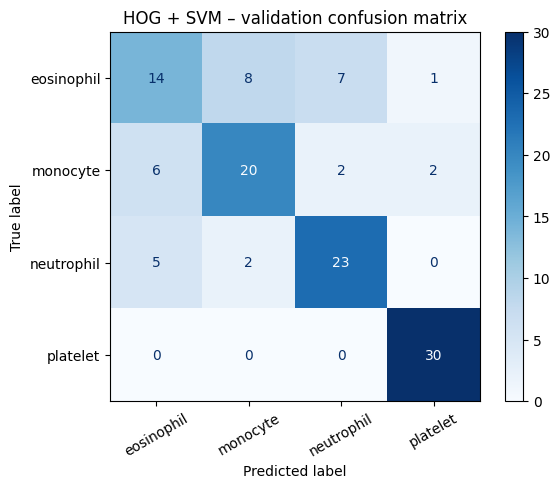

In [8]:
def train_and_choose_C(F_train, y_train, F_val, y_val):
    best_model, best_C, best_acc = None, None, -1
    for C in C_VALUES:
        model = make_pipeline(StandardScaler(), LinearSVC(C=C, max_iter=10000, random_state=SEED))
        model.fit(F_train, y_train)
        acc = accuracy_score(y_val, model.predict(F_val))
        print(f'  C = {C:<4} -> validation accuracy = {acc:.4f}')
        if acc > best_acc:
            best_model, best_C, best_acc = model, C, acc
    print('Best C:', best_C)
    return best_model

def report(model, F_val, y_val, title):
    pred = model.predict(F_val)
    print(f'{title} | Validation accuracy: {accuracy_score(y_val, pred):.4f}'
          f' | Macro-F1: {f1_score(y_val, pred, average="macro"):.4f}')
    cm = confusion_matrix(y_val, pred, labels=CLASSES)
    ConfusionMatrixDisplay(cm, display_labels=names).plot(cmap='Blues', xticks_rotation=30)
    plt.title(f'{title} – validation confusion matrix')
    plt.show()
    return cm

print('HOG + SVM:')
hog_model = train_and_choose_C(H_train, y_train, H_val, y_val)
cm_hog = report(hog_model, H_val, y_val, 'HOG + SVM')

## Q3. SIFT + SVM
### Q3(a) Normal SIFT detection

In [9]:
sift = cv2.SIFT_create()

kp_counts = []
for img in X_train:
    kps, des = sift.detectAndCompute(img, None)
    kp_counts.append(len(kps))
kp_counts = np.array(kp_counts)

print('Average keypoints per image:', round(kp_counts.mean(), 2))
print('Minimum keypoints:', kp_counts.min())
print('Maximum keypoints:', kp_counts.max())
print('Images with zero keypoints:', int((kp_counts == 0).sum()))

Average keypoints per image: 72.97
Minimum keypoints: 8
Maximum keypoints: 178
Images with zero keypoints: 0


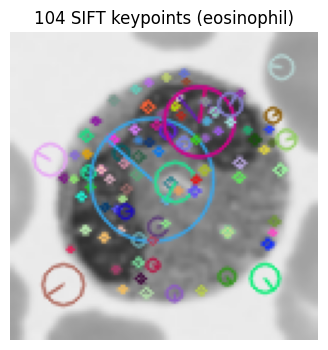

In [10]:
img = X_train[0]
kps, _ = sift.detectAndCompute(img, None)
drawn = cv2.drawKeypoints(img, kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(4, 4))
plt.imshow(drawn)
plt.title(f'{len(kps)} SIFT keypoints ({CLASS_NAMES[y_train[0]]})')
plt.axis('off')
plt.show()

**Why is a different number of keypoints a problem?** An SVM needs every image to be a feature vector of the same length, but each keypoint adds 128 values, so my image with 8 keypoints gives 1024 values while the one with 178 gives 22,784.

### Q3(b) Fixed grid of keypoints (dense SIFT)

In [11]:
# Grid centres: split 128 px into GRID equal parts and take the middle of each part
step = IMG_SIZE / GRID                                   # 128 / 4 = 32
centres = [(i + 0.5) * step for i in range(GRID)]        # 16, 48, 80, 112
grid_kps = [cv2.KeyPoint(x, y, 32) for y in centres for x in centres]   # keypoint size 32
print('Grid centres:', centres, '-> number of keypoints:', len(grid_kps))

def sift_features(img):
    _, des = sift.compute(img, grid_kps)    # des shape: (16, 128)
    return des.flatten()                    # join -> one vector

def sift_all(X):
    return np.array([sift_features(img) for img in X])

S_train, S_val = sift_all(X_train), sift_all(X_val)
print('SIFT feature length:', S_train.shape[1])
print('SIFT train matrix:', S_train.shape, ' val matrix:', S_val.shape)

Grid centres: [16.0, 48.0, 80.0, 112.0] -> number of keypoints: 16
SIFT feature length: 2048
SIFT train matrix: (400, 2048)  val matrix: (120, 2048)


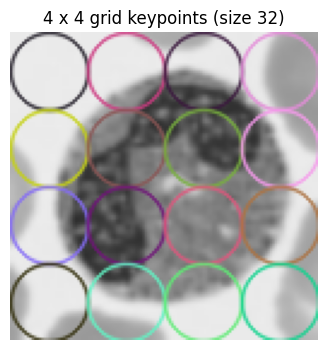

In [12]:
# Show where the grid keypoints sit
drawn = cv2.drawKeypoints(X_train[0], grid_kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(4, 4)); plt.imshow(drawn); plt.title('4 x 4 grid keypoints (size 32)'); plt.axis('off'); plt.show()

**Feature length by hand:** grid points × 128 = (4 × 4) × 128 = 16 × 128 = **2048** ✅ (matches the printed length)

Now **every** image has exactly 16 keypoints, so every image gives a 2048-long vector.

### Q3(c) Train SVM and choose C on the validation set

SIFT + SVM:
  C = 0.1  -> validation accuracy = 0.7417
  C = 1    -> validation accuracy = 0.7417
  C = 10   -> validation accuracy = 0.7417
Best C: 0.1
SIFT + SVM | Validation accuracy: 0.7417 | Macro-F1: 0.7404


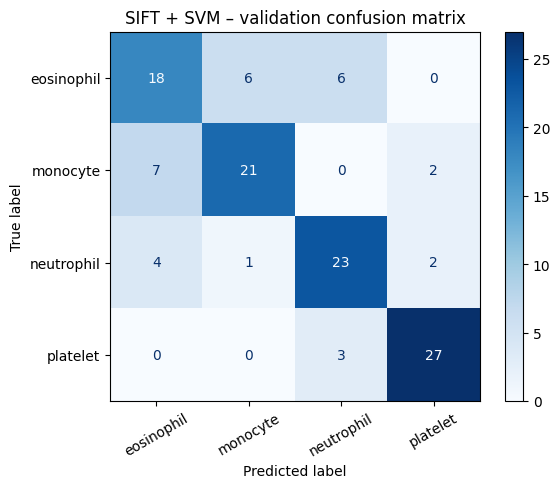

In [19]:
#Note: all three C values give the same validation accuracy because the standardised training data is linearly separable, so C has no effect. Ties keep the smallest C (0.1).
print('SIFT + SVM:')
sift_model = train_and_choose_C(S_train, y_train, S_val, y_val)
cm_sift = report(sift_model, S_val, y_val, 'SIFT + SVM')

## Q4. Robustness
(a)
- **Rotation:** HOG will lose more accuracy because rotation shifts edges across its fixed cells and orientation bins.
- **Noise:** SIFT will lose more accuracy because its finer descriptors are more sensitive to random noise, while HOG's block normalisation helps reduce its effects.

### Q4(b) Test on clean, rotated and noisy images
Both models are **frozen** (no retraining). The change is applied to the image first, then features are extracted.

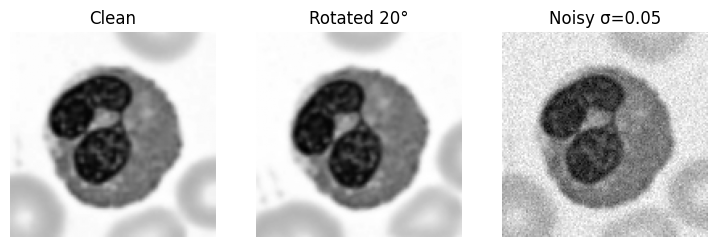

In [14]:
def rotate(img, angle=ROT_ANGLE):
    M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), angle, 1.0)
    return cv2.warpAffine(img, M, (IMG_SIZE, IMG_SIZE), borderMode=cv2.BORDER_REFLECT)   # mirror-fill corners

noise_rng = np.random.default_rng(SEED)              # seeded, so the noise is the same every run

def add_noise(img, sigma=NOISE_SIGMA):
    x = img / 255.0                                   # scale to 0-1
    x = x + noise_rng.normal(0, sigma, x.shape)       # Gaussian noise
    x = np.clip(x, 0, 1)
    return (x * 255).astype(np.uint8)                 # back to 0-255

X_test_rot   = np.array([rotate(img)    for img in X_test])
X_test_noise = np.array([add_noise(img) for img in X_test])

# Visual check of the three versions
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, im, t in zip(axes, [X_test[0], X_test_rot[0], X_test_noise[0]], ['Clean', 'Rotated 20°', 'Noisy σ=0.05']):
    ax.imshow(im, cmap='gray'); ax.set_title(t); ax.axis('off')
plt.show()

In [15]:
test_sets = {'Clean': X_test, 'Rotated': X_test_rot, 'Noisy': X_test_noise}
results = {'HOG + SVM': {}, 'SIFT + SVM': {}}

for case, X in test_sets.items():
    results['HOG + SVM'][case]  = accuracy_score(y_test, hog_model.predict(hog_all(X)))
    results['SIFT + SVM'][case] = accuracy_score(y_test, sift_model.predict(sift_all(X)))

table = pd.DataFrame(results).T
table.columns = ['Clean accuracy', 'Rotated accuracy', 'Noisy accuracy']
print(table.round(4))

            Clean accuracy  Rotated accuracy  Noisy accuracy
HOG + SVM           0.7000            0.6583          0.2667
SIFT + SVM          0.7583            0.7250          0.7417


In [16]:
# Accuracy drop = clean - changed (bigger number = less robust)
for model in table.index:
    print(f"{model}: drop under rotation = {table.loc[model, 'Clean accuracy'] - table.loc[model, 'Rotated accuracy']:.4f}, "
          f"drop under noise = {table.loc[model, 'Clean accuracy'] - table.loc[model, 'Noisy accuracy']:.4f}")

HOG + SVM: drop under rotation = 0.0417, drop under noise = 0.4333
SIFT + SVM: drop under rotation = 0.0333, drop under noise = 0.0167


In [18]:
for case, X in test_sets.items():
    print(case, '| HOG predictions per class:', np.bincount(hog_model.predict(hog_all(X)), minlength=8)[CLASSES])

Clean | HOG predictions per class: [38 27 21 34]
Rotated | HOG predictions per class: [34 30 24 32]
Noisy | HOG predictions per class: [  2 114   2   2]


### Q4(c)
My rotation prediction was correct, but only by one test image (HOG dropped 0.0417, SIFT 0.0333), so the gap is too small to be conclusive. My noise prediction was wrong: HOG fell from 0.7000 to 0.2667 (predictions collapsed to: **Clean** | HOG predictions per class: [38 27 21 34],
**Rotated** |[34 30 24 32],
**Noisy** | HOG predictions per class: [  2 114   2   2]), while SIFT only fell from 0.7583 to 0.7417. So SIFT was more reliable under noise, and neither model lost much under rotation.

## Q5. Short Answers and AI Log
### Q5(a) Theory
**(a) Why does HOG use block normalisation?** Lighting and contrast change the size of gradients across an image, so the same cell can look very different in a bright or dark photo. Normalising each 2 × 2 block makes the histograms depend on the *shape* of the edges rather than how bright they are.

**(b) Why is it wrong to choose C using the test set?** If C is picked because it scores best on the test set, the test set has helped train the model, so its accuracy is no longer an honest estimate on unseen data. The validation set is for tuning; the test set must be touched only once, at the end.

### Q5(b) Which two classes were confused most?

In [17]:
# Add the off-diagonal errors of both models' validation confusion matrices (rows = true, cols = predicted)
errors = cm_hog + cm_sift
np.fill_diagonal(errors, 0)
pair_errors = errors + errors.T                           # count both directions, e.g. A->B and B->A
i, j = np.unravel_index(np.argmax(pair_errors), pair_errors.shape)
print(f'Most confused pair: {names[i]} <-> {names[j]}  ({pair_errors[i, j]} mistakes in total)')

Most confused pair: eosinophil <-> monocyte  (27 mistakes in total)


**Q5(b)**: The models confused *eosinophil and monocyte* the most (27 mistakes). Their main difference is colour (orange-red granules vs blue-grey cytoplasm), and grayscale turns both into similar grey, so they look alike.

Q5(c):
**Prompt:** “Solve this HOG vs SIFT blood-cell lab mid in the simplest way, using my reg. no. 043 settings.”

**What I changed:** I confirmed my settings matched my roll number (43 → seed 43; 3 is odd → 16×16 HOG cells; 3 is in 0–4 → 4×4 SIFT grid). I ran everything myself in Colab on the real BloodMNIST data. When HOG's noisy accuracy came out near 25%, I checked the noise code for a bug before writing my answer. I wrote Q4(c) and Q5(b) based on my own results.

**How I checked it was correct:** I checked the printed class counts (100/30/30 per class), calculated the HOG length (49 blocks × 36 = 1764) and SIFT length (16 × 128 = 2048) by using formula, and matched them to the outputs. I also inspected the example grid, HOG visualisations, keypoint drawings, and clean, rotated, and noisy images side by side to confirm the transformations were applied correctly.